In [1]:
import numpy as np 
import matplotlib.pyplot as plt

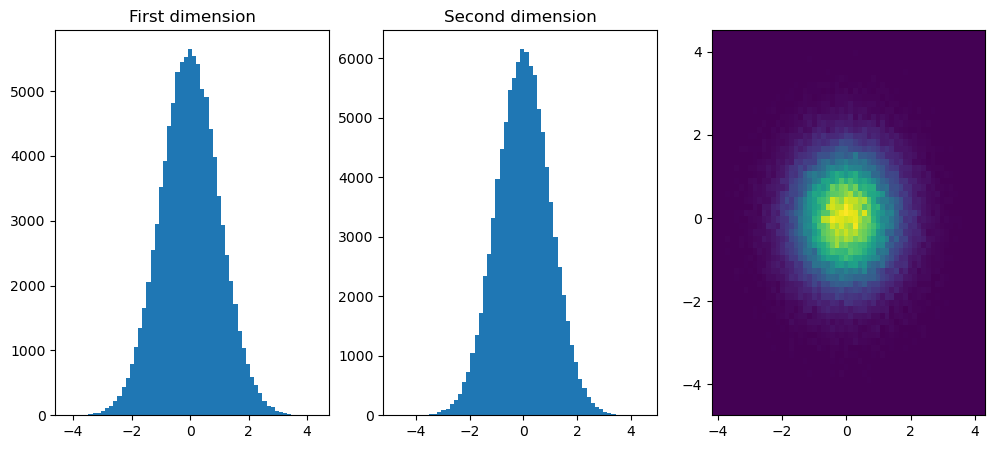

In [46]:
n = 100000

def generate_x(n,d=2):
    #return np.random.multivariate_normal(np.zeros(d), np.ones((d,d)), n)
    return np.random.multivariate_normal(np.zeros(d), np.eye(d), n)

#print(sampling_x(100, 2))

def plot_multivariate(n):
    x = generate_x(n)
    fig,ax = plt.subplots(1, 3, figsize=(12, 5))

    ax[0].hist(x[:,0], bins=60, label='first dimension')
    ax[0].set_title('First dimension')
    ax[1].hist(x[:,1], bins=60, label='second dimension')
    ax[1].set_title('Second dimension')

    ax[2].hist2d(x[:,0], x[:,1], bins=60 , density=True)
    plt.show()

plot_multivariate(n)

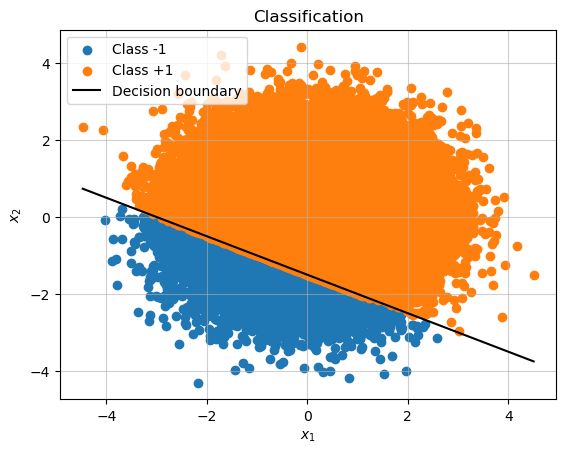

In [63]:
def generate_xy(n,w_star,tau_star):
    x = generate_x(n)
    y = np.array([np.sign(np.dot(w_star, x[i]) + tau_star) for i in range(n)])

    return x,y

w_star = (1,2) #meaning that the boundary is at y=-x/2
tau_star = 3

x,y = generate_xy(n, w_star, tau_star)

def plot_boundary(x, y, w_star, tau_star):
    plt.figure()
    plt.scatter(x[y == -1, 0], x[y == -1, 1], label='Class -1')
    plt.scatter(x[y == 1, 0], x[y == 1, 1], label='Class +1')

    # Decision boundary: w1*x1 + w2*x2 + tau = 0
    x_axis = np.linspace(x[:, 0].min(), x[:, 0].max(), 100)
    y_axis = -(w_star[0] * x_axis + tau_star) / w_star[1]

    plt.plot(x_axis, y_axis, 'k', label='Decision boundary')

    plt.title('Classification')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.legend()
    plt.grid(alpha=0.6)
    
plot_boundary(x,y, w_star, tau_star)
